In [1]:
# Librerías
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve
)


from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.linear_model import LogisticRegressionCV

# 1. Carga y preparación de datos

In [2]:
df = pd.read_csv('data/datos_preprocesados.csv')
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Personas_Cargo,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0,0,0,800.00,2,0,1,0,0,1
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,0,580.00,2,0,0,0,1,0
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,1,0,0,130.00,1,0,0,0,0,0
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,1,0,0,168.08,1,0,1,0,0,1
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,1,0,293.94,0,0,1,0,1,0


In [3]:
# Resultados del análisis financiero
finanzas = pd.read_csv(
    "data/clientes_clasificados_frances_aleman.csv"
)
finanzas.head()

,ID,Monto_Inicial,Ratio_Interes,Duracion,Ingresos,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Al,Intereses_Totales_Fr,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite,Diferencia_Esfuerzo,Ahorro_Intereses_Pct
0,000AIY,53671,16.75,48,50294,36.785600,44.553312,1978.435520,20332.799374,325.557721,Francés,True,7.767711,9.730266
1,000OJE,40000,8.83,36,19018,80.060587,88.680899,232.600374,5677.767041,136.617582,Francés,True,8.620312,4.096688
2,000PLV,26187,8.43,48,69183,11.180782,12.653852,246.691329,4753.801366,84.926147,Alemán,False,1.473070,5.189349
3,000Q3U,78378,14.47,36,50507,64.071137,74.182384,1218.728598,18703.227523,425.573952,Francés,True,10.111247,6.516141
4,000TF1,3913,8.42,36,16000,9.253408,10.211300,20.695805,528.635813,12.771889,Alemán,False,0.957892,3.914946


In [4]:
columnas_financieras = [
    "ID",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al",
    "Ahorro_Intereses_Pct",
    "Sobreesfuerzo_Inicial_Al",
    "Sistema_Recomendado",
    "Ambos_Superan_Limite"
]

In [5]:
# describe de varibales numéricas contínuas
df[['Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Prima', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos']].describe()

,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Prima,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos
count,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000
mean,10.676211,37.255523,0.321933,386.809055,41509.970740,45190.765937,692.053285,212.770601,2.001025
std,3.809254,14.166838,0.181164,267.648386,16036.504202,46648.083692,87.828224,150.688070,1.001298
min,2.010000,12.000000,0.100000,10.000000,16000.000000,3000.000000,398.000000,0.000000,1.000000
25%,7.960000,24.000000,0.140000,138.880000,30484.250000,15126.000000,635.000000,70.000000,1.000000
50%,10.590000,36.000000,0.290000,340.095000,39090.500000,40000.000000,704.000000,208.000000,2.000000
75%,13.270000,48.000000,0.550000,621.670000,50096.750000,47626.500000,761.000000,336.000000,3.000000
max,24.440000,60.000000,0.550000,800.000000,120000.000000,400000.000000,845.000000,639.000000,4.000000


In [6]:
df = df.merge(
    finanzas[columnas_financieras],
    on="ID",
    how="left",
    validate="one_to_one"
)

df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Pct,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,1,0,0,1,36.439698,44.343385,10.107178,372.606139,Francés,True
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,1,0,121.549207,132.165420,3.238250,607.760466,Francés,True
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0,0,0,0,3.752495,4.380152,6.990729,26.152370,Alemán,False
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,1,0,0,1,5.445751,6.108969,4.723142,34.837147,Alemán,False
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,0,1,0,67.845326,74.854640,3.906059,130.262266,Francés,True


In [7]:
print("Dimensiones:", df.shape)

print("\nValores ausentes en variables financieras:")
print(df[columnas_financieras[1:]].isna().sum())

Dimensiones: (178606, 27)

Valores ausentes en variables financieras:
Esfuerzo_Inicial_Fr         0
Esfuerzo_Inicial_Al         0
Ahorro_Intereses_Pct        0
Sobreesfuerzo_Inicial_Al    0
Sistema_Recomendado         0
Ambos_Superan_Limite        0
dtype: int64


In [8]:
# Convertir el booleano a 0 y 1
df["Ambos_Superan_Limite"] = (
    df["Ambos_Superan_Limite"].astype(int)
)

In [9]:
# Para que solo aparezca el esfuerzo del sistema elegido
df["Esfuerzo_Sistema_Elegido"] = np.where(
    df["Sistema_Recomendado"] == "Alemán",
    df["Esfuerzo_Inicial_Al"],
    df["Esfuerzo_Inicial_Fr"]
)

In [10]:
#Transformar las variables financieras
df = pd.get_dummies(
    df,
    columns=["Sistema_Recomendado"],
    drop_first=True,
    dtype=int
)

In [11]:
resumen = pd.DataFrame({
        "Frecuencia": df['Impago'].value_counts(),
        "Porcentaje": (
            df['Impago']
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
        )
    })
resumen

,Frecuencia,Porcentaje
Impago,,
0,157832,88.37
1,20774,11.63


La variable objetivo está desbalanceada: el 88,37 % de las observaciones pertenece a la clase no impago y el 11,63 % a la clase impago. Por este motivo, la exactitud global no es suficiente para evaluar el modelo, ya que un clasificador que siempre predijera la clase mayoritaria alcanzaría un 88,37 % de accuracy sin detectar ningún impago. Por ello, se utilizan métricas como recall, precision, F1, ROC-AUC y PR-AUC.

# 2. División train/test y escalado

Antes de ajustar la regresión logística se excluyen algunas columnas que no deben utilizarse directamente como variables predictoras:
- Impago: es la variable objetivo que el modelo debe predecir. Por tanto, se guarda por separado en y.
- ID: es únicamente un identificador de cada cliente. No representa una característica económica o financiera y podría introducir relaciones artificiales.
- Prima: se excluye porque el objetivo final es calcular la prima a partir del riesgo de impago estimado. Utilizarla para predecir el impago produciría una relación circular y podría generar fuga de información.
- Esfuerzo_Inicial_Fr y Esfuerzo_Inicial_Al: representan el esfuerzo de cuota bajo los dos sistemas posibles. Se sustituyen por Esfuerzo_Sistema_Elegido, que recoge únicamente el esfuerzo correspondiente al sistema recomendado para cada cliente. De este modo se evita introducir información redundante.

In [12]:
columnas_excluir = [
    "Impago",
    "ID",
    "Prima",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al"
]

X = df.drop(columns=columnas_excluir)
y = df["Impago"]

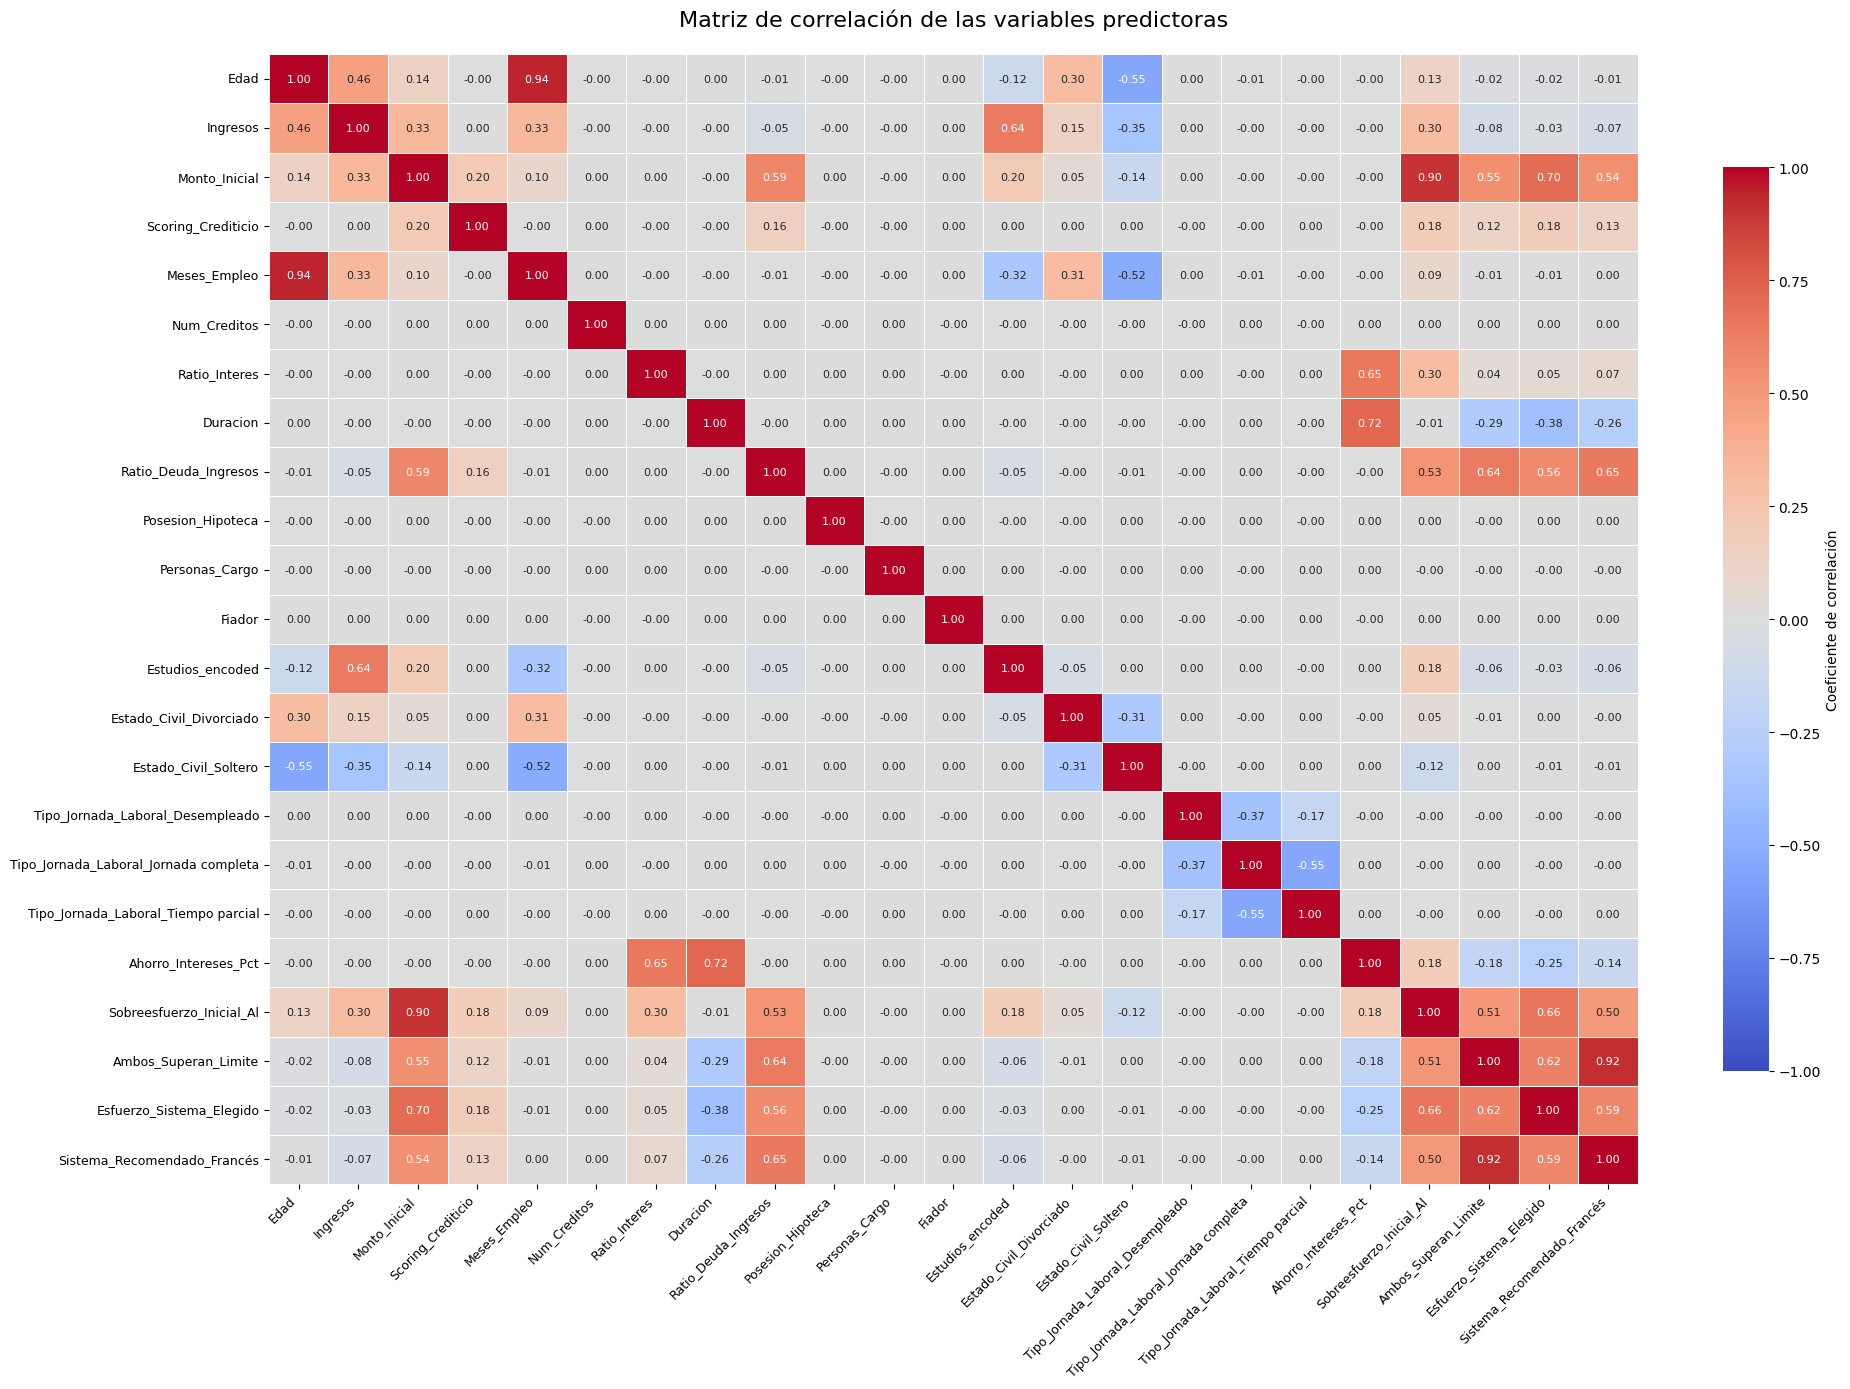

In [13]:
# Matriz de correlación de las variables que realmente entran al modelo
correlacion = X.corr()

plt.figure(figsize=(20, 14))

sns.heatmap(
    correlacion,
    annot=True,          # Mostrar los valores
    fmt=".2f",           # Dos decimales
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 8},
    cbar_kws={
        "label": "Coeficiente de correlación",
        "shrink": 0.8
    }
)

plt.title(
    "Matriz de correlación de las variables predictoras",
    fontsize=16,
    pad=20
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9
)

plt.yticks(
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

In [14]:
columnas_excluir = [
    "Impago",
    "ID",
    "Prima",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al",
    "Edad",
    "Sobreesfuerzo_Inicial_Al",
    "Ambos_Superan_Limite"
]

X = df.drop(columns=columnas_excluir)
y = df["Impago"]

Se eliminaron las variables con correlaciones superiores a 0,90 para reducir la multicolinealidad. Se mantuvo Meses_Empleo frente a Edad por su mayor interpretación crediticia, Monto_Inicial frente a Sobreesfuerzo_Inicial_Al por ser una variable original, y Sistema_Recomendado_Francés frente a Ambos_Superan_Limite para conservar explícitamente el sistema de amortización asignado.

In [15]:
# Variables binarias: columnas que solo contienen 0 y 1
cols_binarias = [
    columna for columna in X.columns
    if set(X[columna].dropna().unique()).issubset({0, 1})
]

# Resto de variables numéricas
cols_num = [
    columna for columna in X.columns
    if columna not in cols_binarias
]

print("Variables numéricas:", cols_num)
print("Variables binarias:", cols_binarias)

Variables numéricas: ['Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Estudios_encoded', 'Ahorro_Intereses_Pct', 'Esfuerzo_Sistema_Elegido']
Variables binarias: ['Posesion_Hipoteca', 'Personas_Cargo', 'Fiador', 'Estado_Civil_Divorciado', 'Estado_Civil_Soltero', 'Tipo_Jornada_Laboral_Desempleado', 'Tipo_Jornada_Laboral_Jornada completa', 'Tipo_Jornada_Laboral_Tiempo parcial', 'Sistema_Recomendado_Francés']


Se estandarizan las variables numéricas no binarias, incluidas las variables codificadas mediante ordinal encoding. Las variables binarias se mantienen con valores 0 y 1. El escalador se ajusta exclusivamente con los datos de entrenamiento y posteriormente se aplica al conjunto de prueba y al conjunto completo.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.8,
    random_state=42,
    shuffle=True,
    stratify=y
)

scaler = StandardScaler()

# Copias para no modificar los conjuntos originales
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Ajustar solamente con las variables numéricas de entrenamiento
X_train_scaled[cols_num] = scaler.fit_transform(
    X_train[cols_num]
)

# Aplicar la misma transformación a test
X_test_scaled[cols_num] = scaler.transform(
    X_test[cols_num]
)

Realizamos predicciones probabilísticas:

- Con .predict_proba() se obtiene, para cada observación, la probabilidad predicha de pertenecer a cada una de las dos clases.

- Con .predict() se obtiene, para cada observación, la clasificación predicha por el modelo. Esta clasificación se corresponde con la clase con mayor probabilidad.


In [17]:
def evaluar_modelo(modelo, X_test, y_test, nombre_modelo="Modelo"):
    
    # Predicción final con umbral 0.5
    prediccion = modelo.predict(X_test)
    
    # Probabilidad de pertenecer a la clase Impago = 1
    probabilidad = modelo.predict_proba(X_test)[:, 1]

    # Métricas principales
    print(f"RESULTADOS: {nombre_modelo}")

    print("\nCantidad de predicciones:")
    print(pd.Series(prediccion).value_counts())

    print("\nInforme de clasificación:")
    print(classification_report(y_test, prediccion))

      # Matriz de confusión gráfica
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediccion,
        display_labels=["No impago", "Impago"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(
        f"Matriz de confusión - {nombre_modelo}"
    )
    plt.show()

    roc_auc = roc_auc_score(y_test, probabilidad)
    pr_auc = average_precision_score(y_test, probabilidad)

    print("ROC-AUC:", round(roc_auc, 3))
    print("PR-AUC:", round(pr_auc, 3))

    # Curva Precision-Recall
    precision, recall, umbrales_pr = precision_recall_curve(
        y_test,
        probabilidad
    )

    tabla_umbrales_pr = pd.DataFrame({
        "Precision": precision[:-1],
        "Recall": recall[:-1],
        "Umbral": umbrales_pr
    })

    # Curva ROC
    fpr, tpr, umbrales_roc = roc_curve(
        y_test,
        probabilidad
    )

    tabla_umbrales_roc = pd.DataFrame({
        "TPR_Recall": tpr,
        "FPR": fpr,
        "Umbral": umbrales_roc
    })

    # Representación de ambas curvas
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Curva Precision-Recall
    axes[0].plot(
        recall,
        precision,
        color="darkorange",
        label=f"PR-AUC = {pr_auc:.3f}"
    )

    # Nivel de referencia: porcentaje de impagos
    proporcion_impagos = y_test.mean()

    axes[0].axhline(
        proporcion_impagos,
        color="grey",
        linestyle="--",
        label=f"Referencia = {proporcion_impagos:.3f}"
    )

    axes[0].set_xlabel("Recall")
    axes[0].set_ylabel("Precision")
    axes[0].set_title(
        f"Curva Precision-Recall — {nombre_modelo}"
    )
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Curva ROC
    axes[1].plot(
        fpr,
        tpr,
        color="steelblue",
        label=f"ROC-AUC = {roc_auc:.3f}"
    )

    axes[1].plot(
        [0, 1],
        [0, 1],
        color="grey",
        linestyle="--",
        label="Clasificación aleatoria"
    )

    axes[1].set_xlabel("Ratio de falsos positivos")
    axes[1].set_ylabel("Ratio de verdaderos positivos")
    axes[1].set_title(
        f"Curva ROC — {nombre_modelo}"
    )
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return tabla_umbrales_pr, tabla_umbrales_roc

# 3. Predicción con sklearn

## 1. class_weight='balanced'

In [18]:
modelo_class_weight = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

modelo_class_weight.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


RESULTADOS: Class Weight

Cantidad de predicciones:
0    21160
1    14562
Name: count, dtype: int64

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.62      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722



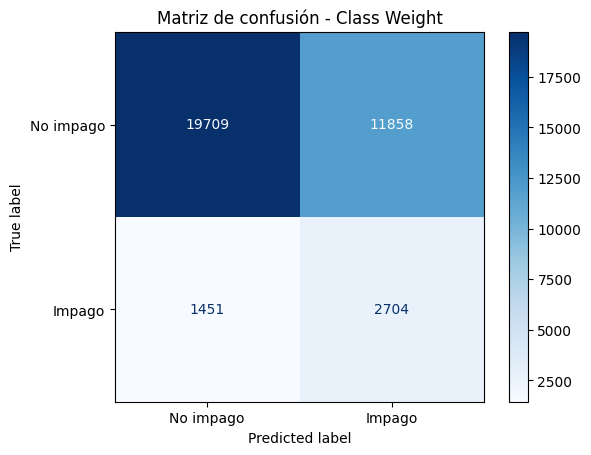

ROC-AUC: 0.688
PR-AUC: 0.223


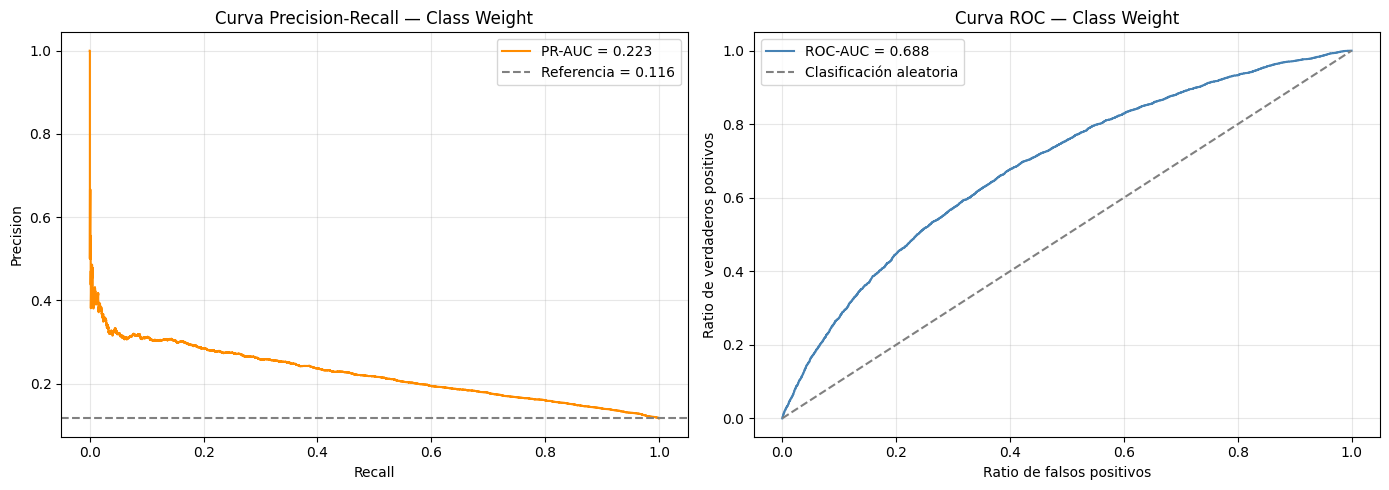

In [19]:
tabla_pr_class, tabla_roc_class = evaluar_modelo(
    modelo_class_weight,
    X_test_scaled,
    y_test,
    nombre_modelo="Class Weight"
)

## 2. RandomOverSampler

Oversampler es una técnica de balanceado, duplica aleatoriamente observaciones de impago hasta igualar las dos clases

In [20]:
oversampler = RandomOverSampler(random_state=42)

X_train_over, y_train_over = oversampler.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribución original:")
print(pd.Series(y_train).value_counts())

print("\nDistribución después del oversampling:")
print(pd.Series(y_train_over).value_counts())

Distribución original:
Impago
0    126265
1     16619
Name: count, dtype: int64

Distribución después del oversampling:
Impago
0    126265
1    126265
Name: count, dtype: int64


In [21]:
modelo_over = LogisticRegression(
    max_iter=2000,
    random_state=42
)

modelo_over.fit(X_train_over, y_train_over)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


RESULTADOS: Oversampling

Cantidad de predicciones:
0    21205
1    14517
Name: count, dtype: int64

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.63      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722



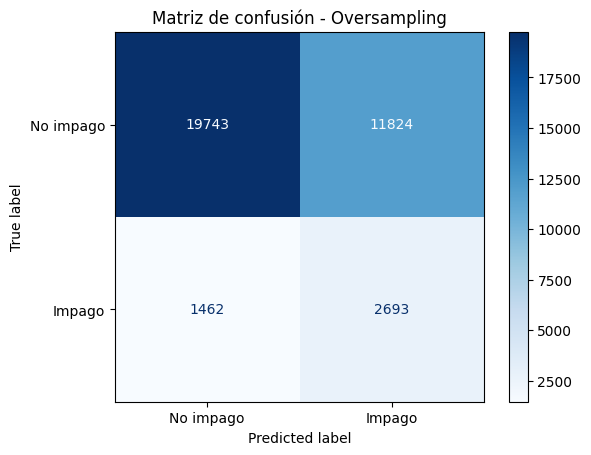

ROC-AUC: 0.688
PR-AUC: 0.223


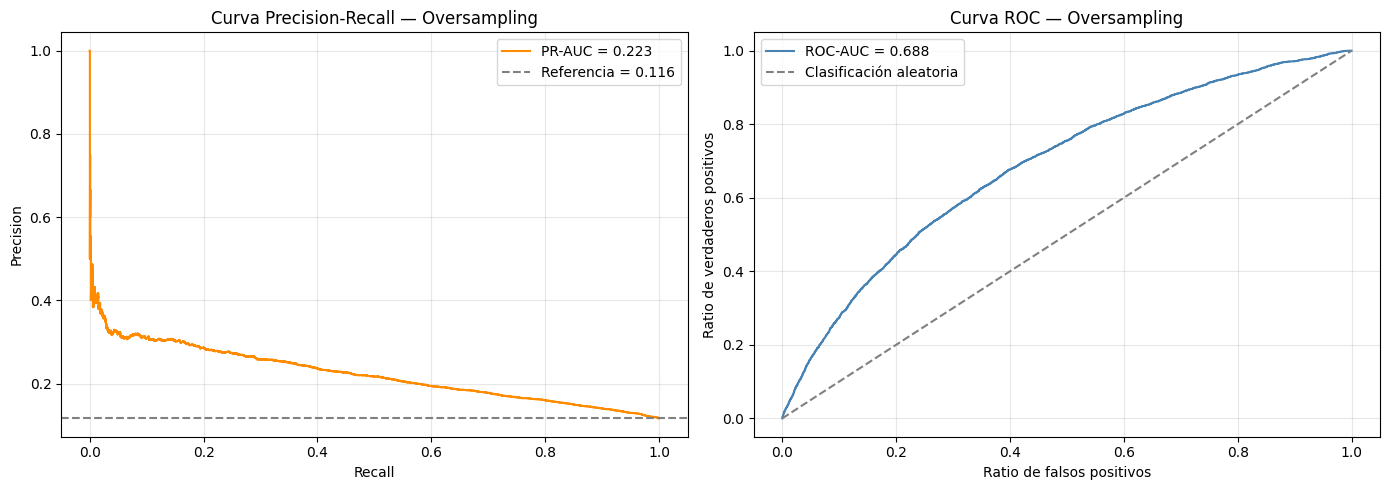

In [22]:
tabla_pr_over, tabla_roc_over = evaluar_modelo(
    modelo_over,
    X_test_scaled,
    y_test,
    nombre_modelo="Oversampling"
)

## 3. RandomUnderSampler

RandomUnderSampler es una técnica de balanceado que reduce la clase mayoritaria hasta igualar las dos clases

In [23]:
undersampler = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = undersampler.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribución original:")
print(pd.Series(y_train).value_counts())

print("\nDistribución después del undersampling:")
print(pd.Series(y_train_under).value_counts())

Distribución original:
Impago
0    126265
1     16619
Name: count, dtype: int64

Distribución después del undersampling:
Impago
0    16619
1    16619
Name: count, dtype: int64


In [24]:
modelo_under = LogisticRegression(
    max_iter=2000,
    random_state=42
)

modelo_under.fit(X_train_under, y_train_under)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


RESULTADOS: Undersampling

Cantidad de predicciones:
0    21091
1    14631
Name: count, dtype: int64

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.62      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.85      0.63      0.69     35722



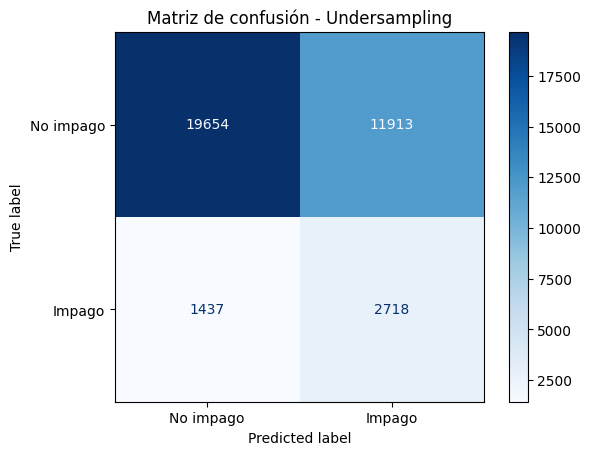

ROC-AUC: 0.688
PR-AUC: 0.223


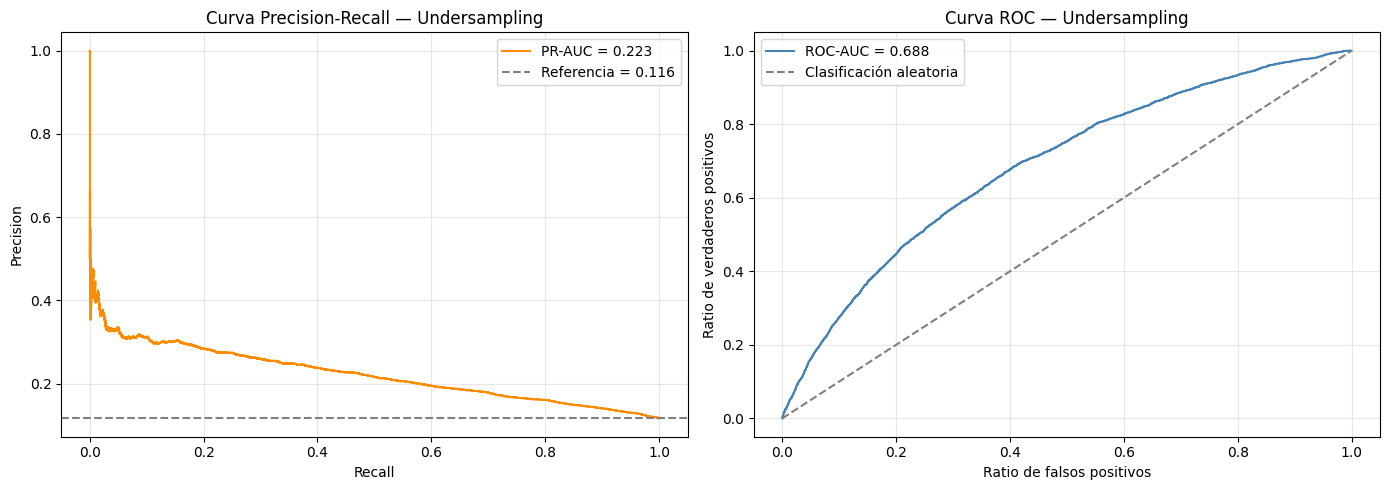

In [25]:
tabla_pr_under, tabla_roc_under = evaluar_modelo(
    modelo_under,
    X_test_scaled,
    y_test,
    nombre_modelo="Undersampling"
)

Las técnicas class_weight, oversampling y undersampling presentan resultados prácticamente equivalentes. Todas alcanzan un ROC-AUC de 0,688 y un PR-AUC de 0,223, con un recall aproximado del 65 % para la clase de impago. Ante la ausencia de diferencias predictivas relevantes, se selecciona el modelo con class_weight='balanced', ya que conserva el conjunto de entrenamiento original y evita tanto la duplicación de observaciones como la pérdida de información.

# 4. Regularización

Aunque la variable objetivo está desbalanceada, se utiliza ROC-AUC para seleccionar el valor de regularización porque el objetivo posterior es trabajar con probabilidades de impago y no únicamente con predicciones binarias. La métrica F1 depende del umbral de clasificación elegido, mientras que ROC-AUC evalúa la capacidad general del modelo para ordenar las observaciones según su riesgo. Adicionalmente, se presenta PR-AUC por ser especialmente informativa ante clases desbalanceadas.

## 1. Lasso

In [26]:
modelo_cv_l1 = LogisticRegressionCV(
    Cs=np.logspace(-4, 4, 50),
    cv=5,
    penalty="l1",
    solver="saga",
    scoring="roc_auc",
    class_weight="balanced", # se añade 'class_weight' porque es el método de balanceo que se ha elegido
    max_iter=5000,
    random_state=42,
)

modelo_cv_l1.fit(
    X_train_scaled,
    y_train
)

,Cs,array([1.0000...00000000e+04])
,fit_intercept,True
,cv,5
,dual,False
,penalty,'l1'
,scoring,'roc_auc'
,solver,'saga'
,tol,0.0001
,max_iter,5000
,class_weight,'balanced'
,n_jobs,None


In [27]:
mejor_C_l1 = modelo_cv_l1.C_[0]

print("Mejor C con regularización L1:", mejor_C_l1)

Mejor C con regularización L1: 0.004291934260128779


RESULTADOS: Regularización L1

Cantidad de predicciones:
0    21094
1    14628
Name: count, dtype: int64

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.62      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722



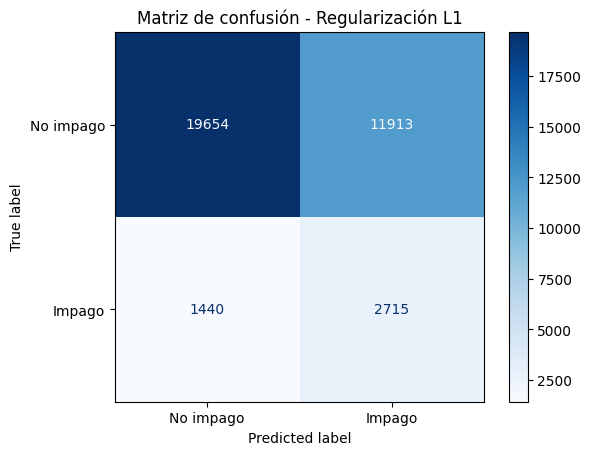

ROC-AUC: 0.688
PR-AUC: 0.223


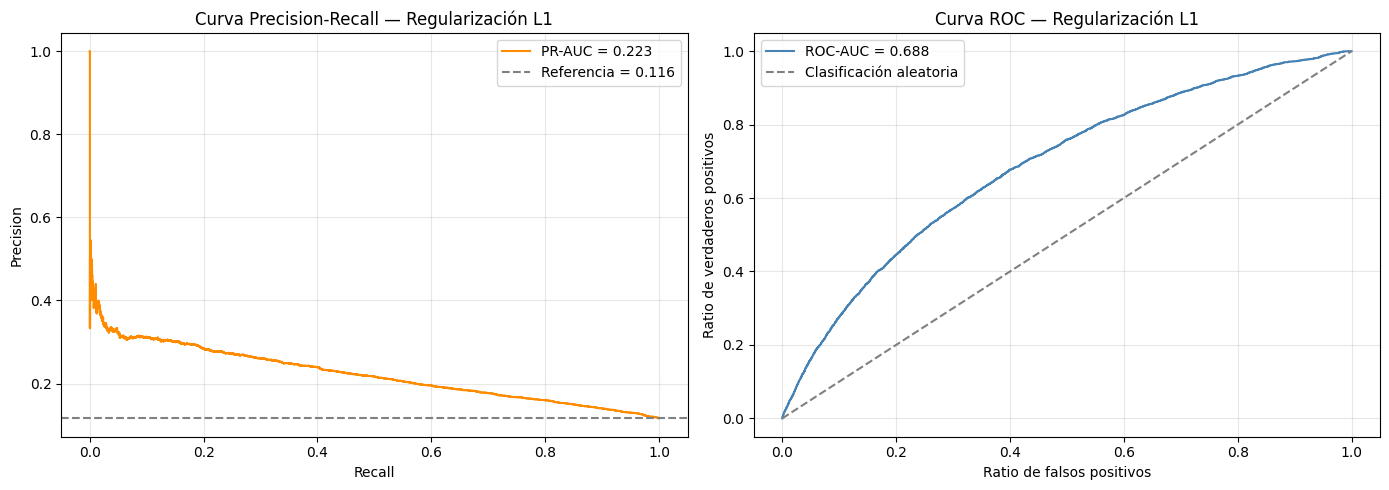

In [28]:
tabla_pr_l1, tabla_roc_l1 = evaluar_modelo(
    modelo_cv_l1,
    X_test_scaled,
    y_test,
    nombre_modelo="Regularización L1"
)

## 2.Ridge

In [29]:
modelo_cv_l2 = LogisticRegressionCV(
    Cs=np.logspace(-4, 4, 50),
    cv=5,
    penalty="l2",
    solver="lbfgs",
    scoring="roc_auc",
    class_weight="balanced", # se añade 'class_weight' porque es el método de balanceo que se ha elegido
    max_iter=5000,
    random_state=42,
)

modelo_cv_l2.fit(
    X_train_scaled,
    y_train
)

,Cs,array([1.0000...00000000e+04])
,fit_intercept,True
,cv,5
,dual,False
,penalty,'l2'
,scoring,'roc_auc'
,solver,'lbfgs'
,tol,0.0001
,max_iter,5000
,class_weight,'balanced'
,n_jobs,None


In [30]:
mejor_C_l2 = modelo_cv_l2.C_[0]

print("Mejor C con regularización L2:", mejor_C_l2)

Mejor C con regularización L2: 0.019306977288832496


RESULTADOS: Regularización L2

Cantidad de predicciones:
0    21176
1    14546
Name: count, dtype: int64

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.62      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722



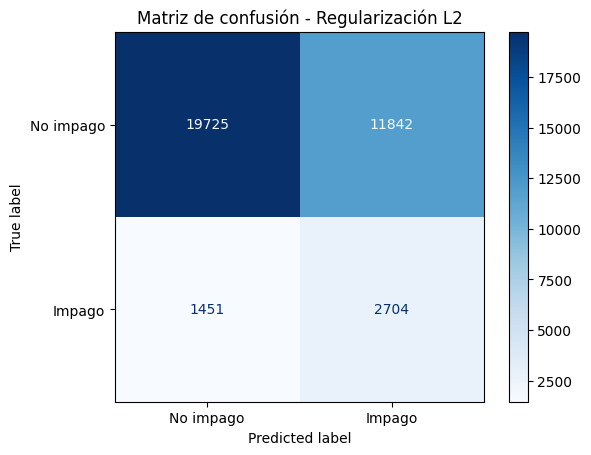

ROC-AUC: 0.688
PR-AUC: 0.223


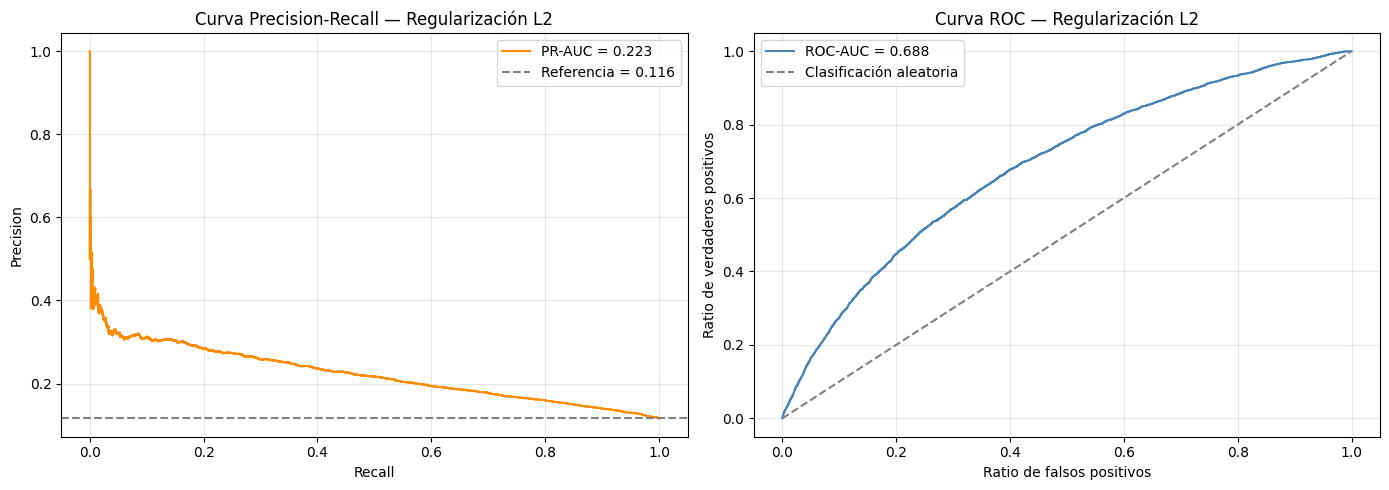

In [31]:
tabla_pr_l2, tabla_roc_l2 = evaluar_modelo(
    modelo_cv_l2,
    X_test_scaled,
    y_test,
    nombre_modelo="Regularización L2"
)

# 5. Modelo final

Se selecciona el modelo de regresión logística con regularización L2 y class_weight='balanced'. L1 y L2 proporcionaron resultados prácticamente iguales, pero L2 se mantiene por ser la configuración estándar y aportar estabilidad a los coeficientes. El balanceo mediante pesos permite tratar el desequilibrio sin eliminar ni duplicar observaciones.

In [32]:
modelo_final = LogisticRegression(
    class_weight="balanced",
    l1_ratio=0,       # Regularización L2
    C=mejor_C_l2,
    max_iter=5000,
    random_state=42
)

In [33]:
modelo_final.fit(X_train_scaled, y_train)

c:\Users\Gaizka\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,np.float64(0....6977288832496)
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,5000
,multi_class,'deprecated'


In [34]:
# Información del modelo
print("Intercept:", modelo_final.intercept_)
print("Coeficiente:", list(zip(X.columns, modelo_final.coef_.flatten(), )))
print("Accuracy de entrenamiento:", modelo_final.score(X_train_scaled, y_train))

Intercept: [-0.18523458]
Coeficiente: [('Ingresos', np.float64(-0.001207048305177148)), ('Monto_Inicial', np.float64(-0.043015508235632924)), ('Scoring_Crediticio', np.float64(-0.10376561839915524)), ('Meses_Empleo', np.float64(-0.5676837575839743)), ('Num_Creditos', np.float64(0.0012184264610316574)), ('Ratio_Interes', np.float64(0.3949607599304566)), ('Duracion', np.float64(-0.04655542472347024)), ('Ratio_Deuda_Ingresos', np.float64(0.02230878164293351)), ('Posesion_Hipoteca', np.float64(-0.030000290491803545)), ('Personas_Cargo', np.float64(-0.0011150494243371586)), ('Fiador', np.float64(-0.004134961567397827)), ('Estudios_encoded', np.float64(-0.07666938362498735)), ('Estado_Civil_Divorciado', np.float64(0.017821712041693288)), ('Estado_Civil_Soltero', np.float64(0.046490779797633386)), ('Tipo_Jornada_Laboral_Desempleado', np.float64(0.011328300394554063)), ('Tipo_Jornada_Laboral_Jornada completa', np.float64(0.0194594094736989)), ('Tipo_Jornada_Laboral_Tiempo parcial', np.float64(

Un coeficiente positivo indica que, manteniendo constantes el resto de las variables, un aumento de esa variable incrementa el riesgo estimado de impago. Un coeficiente negativo indica una reducción del riesgo. El odds ratio facilita la interpretación: valores superiores a 1 indican un aumento de las odds de impago y valores inferiores a 1 indican una disminución.

## Análisis estadístico con statsmodels

In [35]:
# Interpretación del modelo final
coeficientes_finales = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo_final.coef_[0],
    "Odds_ratio": np.exp(modelo_final.coef_[0])
})

# Ordenar desde el coeficiente más positivo al más negativo
coeficientes_finales = coeficientes_finales.sort_values(
    by="Coeficiente",
    ascending=False
)

print("Intercepto:", modelo_final.intercept_[0])

coeficientes_finales

Intercepto: -0.18523457917159675


,Variable,Coeficiente,Odds_ratio
5,Ratio_Interes,0.394961,1.484326
13,Estado_Civil_Soltero,0.046491,1.047588
17,Ahorro_Intereses_Pct,0.039862,1.040667
7,Ratio_Deuda_Ingresos,0.022309,1.022559
15,Tipo_Jornada_Laboral_Jornada completa,0.019459,1.019650
12,Estado_Civil_Divorciado,0.017822,1.017981
16,Tipo_Jornada_Laboral_Tiempo parcial,0.016727,1.016867
14,Tipo_Jornada_Laboral_Desempleado,0.011328,1.011393
4,Num_Creditos,0.001218,1.001219
9,Personas_Cargo,-0.001115,0.998886


Para interpretar el modelo final se analizan sus coeficientes y odds ratios. Un coeficiente positivo indica que el aumento de la variable incrementa el riesgo estimado de impago, mientras que un coeficiente negativo indica una reducción del riesgo, manteniendo constantes las demás variables. Un odds ratio superior a 1 indica un aumento de las odds de impago, mientras que un valor inferior a 1 indica una disminución.

In [36]:
# # Creación del modelo utilizando matrices como sklearn
X_train_stats = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_train_stats = sm.add_constant(
    X_train_stats,
    prepend=True
)

modelo_log_statsm = sm.Logit(
    endog=y_train,
    exog=X_train_stats
).fit()

print(modelo_log_statsm.summary())

Optimization terminated successfully.
         Current function value: 0.335932
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:               142884
Model:                          Logit   Df Residuals:                   142863
Method:                           MLE   Df Model:                           20
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                 0.06558
Time:                        15:37:08   Log-Likelihood:                -47999.
converged:                       True   LL-Null:                       -51368.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -2.2150      

El modelo de statsmodels se ajusta como análisis estadístico complementario para obtener los p-valores. No coincide exactamente con el modelo predictivo final, ya que no incorpora la ponderación de clases ni la regularización L2.

El modelo resulta globalmente significativo, ya que el p-valor de la prueba de razón de verosimilitudes es inferior a 0,05. Por tanto, se rechaza la hipótesis nula de que todos los coeficientes sean simultáneamente iguales a cero y se concluye que, en conjunto, las variables aportan capacidad explicativa sobre el impago.
Las variables estadísticamente significativas al 5 % son Monto_Inicial, Scoring_Crediticio, Meses_Empleo, Ratio_Interes, Estudios_encoded y Sistema_Recomendado_Francés. Entre ellas, Ratio_Interes presenta una relación positiva con el riesgo de impago, mientras que Monto_Inicial, Scoring_Crediticio, Meses_Empleo, Estudios_encoded y Sistema_Recomendado_Francés presentan coeficientes negativos.
El pseudo R² de McFadden es aproximadamente 0,066, lo que indica una capacidad explicativa moderada. No obstante, este valor no debe interpretarse de la misma forma que el R² de una regresión lineal.
El resto de las variables no presenta evidencia estadística suficiente para afirmar que su efecto individual sea distinto de cero al nivel de significación del 5 %, manteniendo constantes las demás variables. Esto no implica necesariamente que deban eliminarse del modelo predictivo, especialmente porque el modelo final utiliza regularización L2.

## Intervalos de confianza de los coeficientes

In [37]:
intervalos_ci = modelo_log_statsm.conf_int(alpha=0.05).rename(columns={0: "2.5%", 1: "97.5%"})

intervalos_ci[:21]

,2.5%,97.5%
const,-2.273521,-2.156461
Ingresos,-0.038131,0.033559
Monto_Inicial,-0.077289,-0.004889
Scoring_Crediticio,-0.118041,-0.084829
Meses_Empleo,-0.606358,-0.543655
Num_Creditos,-0.018421,0.014785
Ratio_Interes,0.336527,0.436518
Duracion,-0.108077,0.013813
Ratio_Deuda_Ingresos,-0.005557,0.044536
Posesion_Hipoteca,-0.055054,0.014720


## Evaluar modelo final

RESULTADOS: Modelo final: Class Weight + L2

Cantidad de predicciones:
0    21173
1    14549
Name: count, dtype: int64

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.62      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722



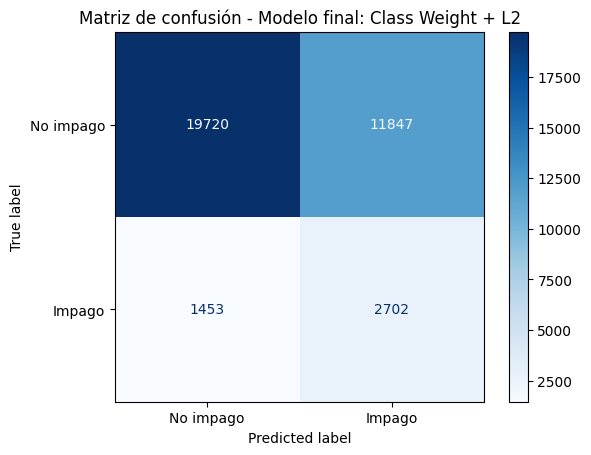

ROC-AUC: 0.688
PR-AUC: 0.223


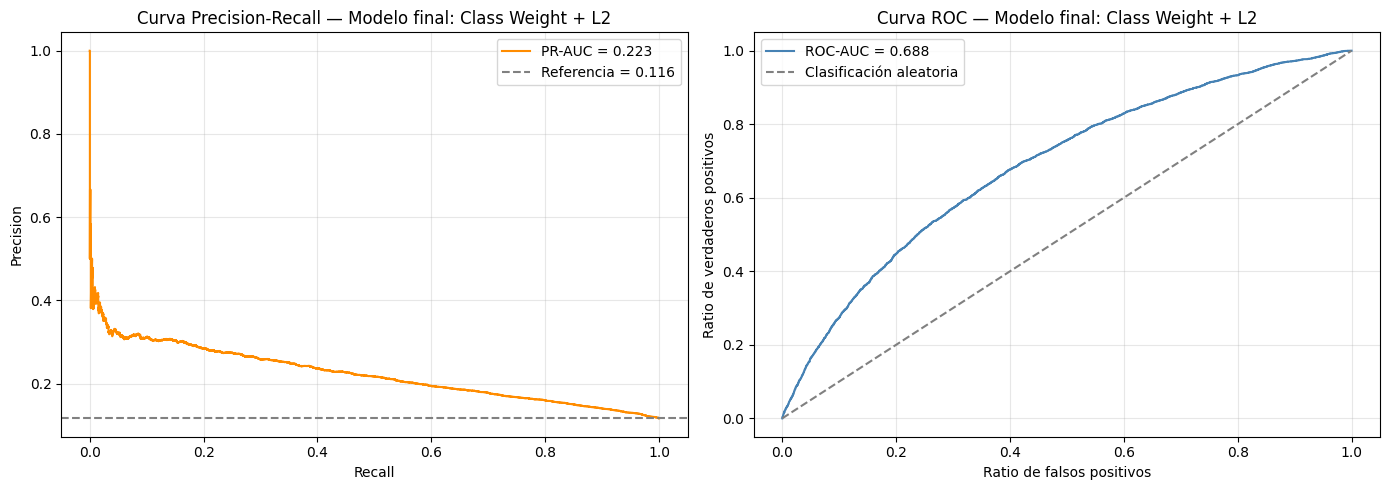

In [38]:
tabla_pr_final, tabla_roc_final = evaluar_modelo(
    modelo_final,
    X_test_scaled,
    y_test,
    nombre_modelo="Modelo final: Class Weight + L2"
)

**Predict proba como variable para el modelo de prima**

Con .predict_proba() se obtiene, para cada observación, la probabilidad predicha de pertenecer a cada una de las dos clases.

Para el cálculo de la prima se utilizará la probabilidad de impago obtenida mediante predict_proba, en lugar de la predicción binaria generada por predict.
La predicción binaria únicamente clasifica cada préstamo como:
- 0: no impago.
- 1: impago.

Esta clasificación elimina información relevante, ya que dos clientes con probabilidades de impago muy diferentes pueden recibir la misma categoría. Por ejemplo, un cliente con una probabilidad del 51 % y otro con una probabilidad del 90 % serían clasificados como impago, aunque el riesgo asociado al segundo sea mucho mayor.

Una vez seleccionado y evaluado el modelo final, se aplica predict_proba a todas las observaciones del dataset utilizando las mismas variables, el mismo orden de columnas y el escalado aprendido con el conjunto de entrenamiento. De esta forma se obtiene un indicador continuo del riesgo de impago para cada cliente, que posteriormente se utilizará en el modelo de cálculo de la prima.

In [39]:
X_total_scaled = X.copy()

X_total_scaled[cols_num] = scaler.transform(
    X[cols_num]
)

# Escalado de las columnas numéricas
X_total_scaled = X_total_scaled[X_train_scaled.columns]

# Probabilidades de pago e impago
probs = modelo_final.predict_proba(X_total_scaled)

In [40]:
# Incorporar probabilidades al dataset original
df_prob = df.copy()
df_prob["Probabilidad_Impago"] = probs[:, 1]

df_prob.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Pct,Sobreesfuerzo_Inicial_Al,Ambos_Superan_Limite,Esfuerzo_Sistema_Elegido,Sistema_Recomendado_Francés,Probabilidad_Impago
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0,1,36.439698,44.343385,10.107178,372.606139,1,36.439698,1,0.618775
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,1,0,121.549207,132.165420,3.238250,607.760466,1,121.549207,1,0.398983
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0,0,3.752495,4.380152,6.990729,26.152370,0,4.380152,0,0.451483
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,0,1,5.445751,6.108969,4.723142,34.837147,0,6.108969,0,0.412336
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,0,67.845326,74.854640,3.906059,130.262266,1,67.845326,1,0.569220


In [41]:
df_prob.to_csv(
    "data/datos_con_probabilidad_impago.csv",
    index=False
)